# 05 — Nested CV + XGBoost tuning com `sample_weight`

**Hipótese a testar:** o XGBoost foi significativamente pior que KNN/LDA/LogReg no notebook 04 (p=0.002) por **decorar a classe majoritária** (COPD = 76% dos pacientes). Vamos testar se:

1. Adicionar `sample_weight` inversamente proporcional à frequência da classe corrige o viés.
2. Tuning de hiperparâmetros (com `GridSearchCV` em CV interno) melhora ainda mais.

**Por que Nested CV:** se tunamos no mesmo CV em que avaliamos, vazamos informação e o score fica otimista. Solução padrão-ouro:
- **CV externo** (`StratifiedGroupKFold` × repetições) — só pra estimar desempenho final.
- **CV interno** (`StratifiedGroupKFold` dentro de `GridSearchCV`) — só pra escolher hiperparâmetros.

Todos os splits são por paciente (`groups=patient_id`).

In [1]:
import sys, time, warnings
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                              confusion_matrix, classification_report)
from xgboost import XGBClassifier

from src import config

warnings.filterwarnings('ignore', category=UserWarning)
sns.set_theme(style='whitegrid')

## 1. Dados

In [2]:
feats_df = pd.read_csv(config.PROCESSED_DIR / 'features.csv')
FEATURE_COLS = [c for c in feats_df.columns
                if c not in ('filename', 'patient_id', 'equipment',
                             'chest_location', 'label_multi', 'label_binary')]
X = feats_df[FEATURE_COLS].values
le = LabelEncoder()
y = le.fit_transform(feats_df['label_multi'])
groups = feats_df['patient_id'].values
CLASSES = list(le.classes_)
sample_w = compute_sample_weight('balanced', y)
print(f'X: {X.shape} | Classes: {CLASSES}')
print(f'Pesos por classe: {dict(zip(CLASSES, [sample_w[y==i][0] for i in range(len(CLASSES))]))}')
print(f'Pacientes: {len(np.unique(groups))}')

X: (851, 78) | Classes: ['COPD', 'Healthy', 'URTI']
Pesos por classe: {'COPD': np.float64(0.3577133249264397), 'Healthy': np.float64(8.104761904761904), 'URTI': np.float64(12.333333333333334)}
Pacientes: 104


## 2. Modelos a comparar

- **XGB-default**: configuração do notebook 04 (perdedor).
- **XGB-balanced**: mesmo XGB + `sample_weight` balanceado.
- **XGB-tuned**: tuning de `max_depth`, `learning_rate`, `n_estimators`, `min_child_weight` via GridSearch + `sample_weight`.
- **KNN**: campeão do notebook 04 (referência).
- **LDA**: também top no notebook 04 (referência interpretável).

Grade pequena (`3×3×2×2 = 36 combos`) por orçamento de tempo.

In [3]:
def xgb_pipe(**kw):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('clf', XGBClassifier(eval_metric='mlogloss', n_jobs=1,
                              tree_method='hist', **kw)),
    ])

XGB_DEFAULT = xgb_pipe(n_estimators=300, max_depth=5, learning_rate=0.1)

XGB_GRID = {
    'clf__n_estimators': [200, 400],
    'clf__max_depth':    [3, 5, 7],
    'clf__learning_rate':[0.05, 0.1, 0.2],
    'clf__min_child_weight': [1, 3],
}
print('combos no grid:', 2*3*3*2)

KNN_PIPE = Pipeline([('scaler', StandardScaler()),
                     ('clf', KNeighborsClassifier(n_neighbors=5, weights='distance'))])
LDA_PIPE = Pipeline([('scaler', StandardScaler()),
                     ('clf', LinearDiscriminantAnalysis())])

combos no grid: 36


## 3. Função de avaliação Nested CV

Para cada fold externo:
1. Separa treino/teste por paciente.
2. Treina o modelo (com GridSearch interno se aplicável).
3. Prediz no teste externo.
Acumula predições out-of-fold em todo o dataset → métricas finais agregadas.

In [4]:
def patient_metrics(y_true, y_pred, patient_ids):
    df = pd.DataFrame({'pid': patient_ids, 'y': y_true, 'pred': y_pred})
    agg = df.groupby('pid').agg(
        y=('y', 'first'),
        pred=('pred', lambda s: s.value_counts().idxmax()),
    )
    return agg['y'].values, agg['pred'].values

def eval_one_outer(model, Xtr, ytr, gtr, Xte, gtr_idx, use_weights=False,
                    grid=None, inner_splits=3, inner_seed=0):
    fit_params = {}
    if use_weights:
        wtr = compute_sample_weight('balanced', ytr)
        fit_params['clf__sample_weight'] = wtr
    if grid is not None:
        inner = StratifiedGroupKFold(n_splits=inner_splits, shuffle=True,
                                      random_state=inner_seed)
        gs = GridSearchCV(model, param_grid=grid, scoring='f1_macro',
                          cv=inner.split(Xtr, ytr, groups=gtr),
                          n_jobs=-1, refit=True)
        gs.fit(Xtr, ytr, **fit_params)
        return gs.predict(Xte), gs.best_params_
    else:
        model.fit(Xtr, ytr, **fit_params)
        return model.predict(Xte), None

def run_nested(model_factory, name, *, use_weights=False, grid=None,
                 outer_repeats=3, outer_splits=5, inner_splits=3):
    t0 = time.time()
    fold_records = []
    best_params_all = []
    for rep in range(outer_repeats):
        seed = 42 + rep
        outer = StratifiedGroupKFold(n_splits=outer_splits, shuffle=True, random_state=seed)
        for fold, (tr, te) in enumerate(outer.split(X, y, groups)):
            model = model_factory()
            y_pred_te, best = eval_one_outer(
                model, X[tr], y[tr], groups[tr], X[te], None,
                use_weights=use_weights, grid=grid,
                inner_splits=inner_splits, inner_seed=seed)
            if best is not None:
                best_params_all.append(best)
            # nivel gravacao no fold
            f1m_r = f1_score(y[te], y_pred_te, average='macro')
            acc_r = accuracy_score(y[te], y_pred_te)
            # nivel paciente no fold
            yt_p, yp_p = patient_metrics(y[te], y_pred_te, groups[te])
            f1m_p = f1_score(yt_p, yp_p, average='macro') if len(set(yt_p)) > 1 else np.nan
            acc_p = accuracy_score(yt_p, yp_p)
            rec_p = recall_score(yt_p, yp_p, average='macro')
            fold_records.append(dict(model=name, repeat=rep, fold=fold,
                                      acc_rec=acc_r, f1m_rec=f1m_r,
                                      acc_pat=acc_p, f1m_pat=f1m_p, recall_pat=rec_p))
        print(f'  {name} rep {rep+1}/{outer_repeats} ({time.time()-t0:.0f}s)')
    return pd.DataFrame(fold_records), best_params_all

## 4. Executar a comparação

**Atenção ao tempo:** o XGB-tuned roda 36 combos × 3 inner folds × 15 outer folds = 1620 fits de XGB. Tempo estimado: 5–10 min.

In [5]:
all_results = []
best_params_log = {}

configs = [
    ('XGB-default',  lambda: xgb_pipe(n_estimators=300, max_depth=5, learning_rate=0.1), False, None),
    ('XGB-balanced', lambda: xgb_pipe(n_estimators=300, max_depth=5, learning_rate=0.1), True,  None),
    ('XGB-tuned',    lambda: xgb_pipe(),                                                   True,  XGB_GRID),
    ('KNN',          lambda: Pipeline([('scaler', StandardScaler()),
                                       ('clf', KNeighborsClassifier(n_neighbors=5, weights='distance'))]),
                                       False, None),
    ('LDA',          lambda: Pipeline([('scaler', StandardScaler()),
                                       ('clf', LinearDiscriminantAnalysis())]),
                                       False, None),
]

for name, factory, use_w, grid in configs:
    print(f'>>> {name}')
    df, bps = run_nested(factory, name, use_weights=use_w, grid=grid,
                          outer_repeats=3, outer_splits=5, inner_splits=3)
    all_results.append(df)
    if bps:
        best_params_log[name] = bps

res_df = pd.concat(all_results, ignore_index=True)
print('\nTotal fold-rows:', len(res_df))

>>> XGB-default


  XGB-default rep 1/3 (5s)


  XGB-default rep 2/3 (8s)


  XGB-default rep 3/3 (11s)
>>> XGB-balanced


  XGB-balanced rep 1/3 (3s)


  XGB-balanced rep 2/3 (5s)


... (3 outputs left out)

  XGB-tuned rep 3/3 (72s)
>>> KNN


  KNN rep 1/3 (3s)
  KNN rep 2/3 (3s)


  KNN rep 3/3 (3s)
>>> LDA
  LDA rep 1/3 (0s)


  LDA rep 2/3 (0s)
  LDA rep 3/3 (0s)

Total fold-rows: 75


## 5. Sumário — média ± desvio por modelo (15 outer folds)

In [6]:
def fmt(mu, sd): return f'{mu:.3f} ± {sd:.3f}'

summary = res_df.groupby('model').agg(
    f1m_rec_mu=('f1m_rec', 'mean'), f1m_rec_sd=('f1m_rec', 'std'),
    f1m_pat_mu=('f1m_pat', 'mean'), f1m_pat_sd=('f1m_pat', 'std'),
    rec_pat_mu=('recall_pat', 'mean'), rec_pat_sd=('recall_pat', 'std'),
    acc_pat_mu=('acc_pat', 'mean'), acc_pat_sd=('acc_pat', 'std'),
).sort_values('f1m_pat_mu', ascending=False)

pretty = pd.DataFrame({
    'F1m gravação': [fmt(r.f1m_rec_mu, r.f1m_rec_sd) for r in summary.itertuples()],
    'F1m paciente': [fmt(r.f1m_pat_mu, r.f1m_pat_sd) for r in summary.itertuples()],
    'Recall macro pac.': [fmt(r.rec_pat_mu, r.rec_pat_sd) for r in summary.itertuples()],
    'Acc paciente':  [fmt(r.acc_pat_mu, r.acc_pat_sd) for r in summary.itertuples()],
}, index=summary.index)
pretty

,F1m gravação,F1m paciente,Recall macro pac.,Acc paciente
model,,,,
KNN,0.580 ± 0.076,0.579 ± 0.121,0.591 ± 0.112,0.739 ± 0.075
LDA,0.562 ± 0.067,0.575 ± 0.120,0.589 ± 0.124,0.744 ± 0.059
XGB-tuned,0.574 ± 0.122,0.556 ± 0.140,0.559 ± 0.137,0.738 ± 0.095
XGB-balanced,0.552 ± 0.107,0.529 ± 0.118,0.536 ± 0.117,0.720 ± 0.079
XGB-default,0.551 ± 0.116,0.527 ± 0.116,0.533 ± 0.107,0.732 ± 0.075


## 6. Distribuição (boxplot) e ICs95 bootstrap

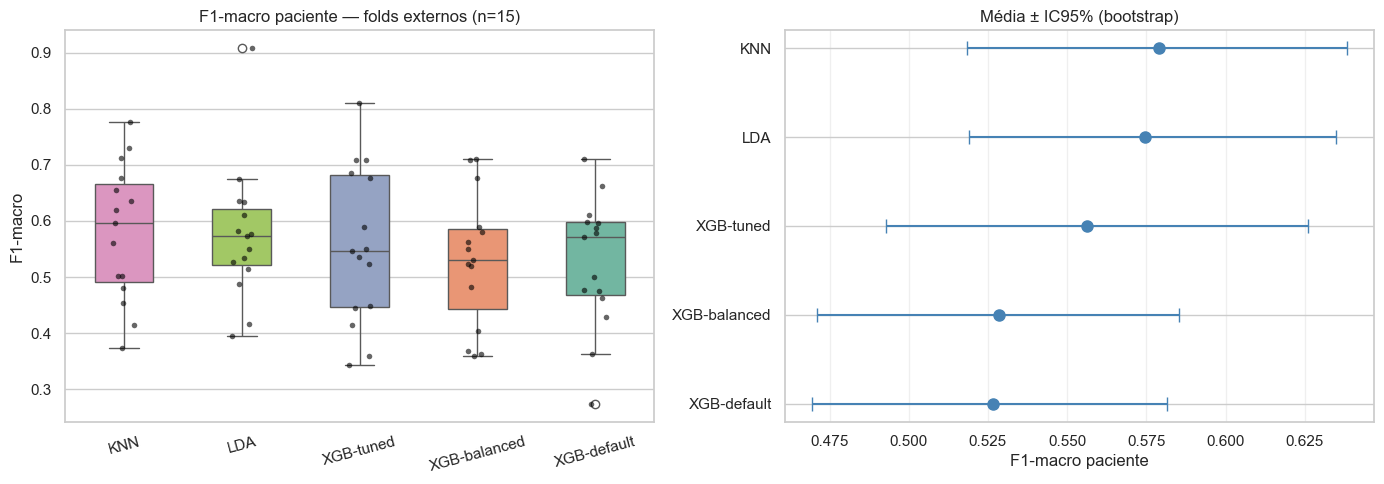

,model,mean,lo,hi
0,KNN,0.579,0.518,0.638
1,LDA,0.575,0.519,0.635
2,XGB-tuned,0.556,0.493,0.626
3,XGB-balanced,0.529,0.471,0.585
4,XGB-default,0.527,0.469,0.582


In [7]:
order = summary.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=res_df, x='model', y='f1m_pat', order=order, hue='model',
            palette='Set2', legend=False, width=0.5, ax=axes[0])
sns.stripplot(data=res_df, x='model', y='f1m_pat', order=order,
              color='black', size=4, alpha=0.6, ax=axes[0])
axes[0].set_title('F1-macro paciente — folds externos (n=15)')
axes[0].set_ylabel('F1-macro'); axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=15)

def boot_ci(arr, n=2000, ci=95, seed=0):
    rng = np.random.default_rng(seed)
    arr = np.asarray(arr); arr = arr[~np.isnan(arr)]
    means = rng.choice(arr, size=(n, len(arr)), replace=True).mean(axis=1)
    lo, hi = np.percentile(means, [(100-ci)/2, 100-(100-ci)/2])
    return arr.mean(), lo, hi

ci_rows = []
for m in order:
    arr = res_df.loc[res_df['model']==m, 'f1m_pat'].values
    mu, lo, hi = boot_ci(arr)
    ci_rows.append(dict(model=m, mean=mu, lo=lo, hi=hi))
ci_df = pd.DataFrame(ci_rows)

y_pos = np.arange(len(ci_df))
axes[1].errorbar(ci_df['mean'], y_pos,
                  xerr=[ci_df['mean']-ci_df['lo'], ci_df['hi']-ci_df['mean']],
                  fmt='o', color='steelblue', capsize=5, markersize=8)
axes[1].set_yticks(y_pos); axes[1].set_yticklabels(ci_df['model'])
axes[1].set_xlabel('F1-macro paciente'); axes[1].set_title('Média ± IC95% (bootstrap)')
axes[1].invert_yaxis(); axes[1].grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()
ci_df.round(3)

## 7. Wilcoxon pareado — XGB-tuned vs cada baseline

In [8]:
def paired_wilcoxon(a_name, b_name, col='f1m_pat'):
    a = res_df.loc[res_df['model']==a_name, col].values
    b = res_df.loc[res_df['model']==b_name, col].values
    try:
        _, p = stats.wilcoxon(a, b)
    except ValueError:
        p = np.nan
    return p, np.mean(a) - np.mean(b)

pairs = [('XGB-tuned', 'XGB-default'),
         ('XGB-tuned', 'XGB-balanced'),
         ('XGB-tuned', 'KNN'),
         ('XGB-tuned', 'LDA'),
         ('XGB-balanced', 'XGB-default')]
rows = []
for a, b in pairs:
    p, delta = paired_wilcoxon(a, b)
    rows.append(dict(comparison=f'{a} vs {b}',
                      delta_F1m=round(delta, 3),
                      p_value=round(p, 4),
                      significant=p<0.05))
pd.DataFrame(rows)

,comparison,delta_F1m,p_value,significant
0,XGB-tuned vs XGB-default,0.030,0.1514,False
1,XGB-tuned vs XGB-balanced,0.028,0.1141,False
2,XGB-tuned vs KNN,-0.023,0.5509,False
3,XGB-tuned vs LDA,-0.018,0.7615,False
4,XGB-balanced vs XGB-default,0.002,0.8613,False


## 8. Best params do XGB-tuned — escolhidos pelo CV interno

Qual configuração foi escolhida mais frequentemente nos 15 outer folds? Indica regime estável de hiperparâmetros.

In [9]:
if 'XGB-tuned' in best_params_log:
    bps = pd.DataFrame(best_params_log['XGB-tuned'])
    print('Frequência de cada hiperparâmetro escolhido:\n')
    for col in bps.columns:
        print(f'-- {col} --')
        print(bps[col].value_counts().to_string())
        print()
else:
    print('Sem best_params_log.')

Frequência de cada hiperparâmetro escolhido:

-- clf__learning_rate --
clf__learning_rate
0.05    10
0.20     4
0.10     1

-- clf__max_depth --
clf__max_depth
3    8
7    5
5    2

-- clf__min_child_weight --
clf__min_child_weight
1    10
3     5

-- clf__n_estimators --
clf__n_estimators
200    14
400     1



## 9. Matriz de confusão do melhor modelo (paciente)

Refita o melhor modelo no dataset todo e mostra a matriz a nível de paciente (via predições out-of-fold já calculadas, agregadas por voto).

Melhor modelo: KNN


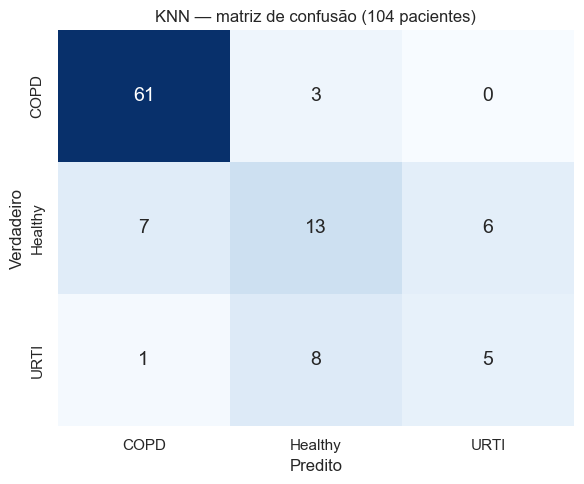

              precision    recall  f1-score   support

        COPD      0.884     0.953     0.917        64
     Healthy      0.542     0.500     0.520        26
        URTI      0.455     0.357     0.400        14

    accuracy                          0.760       104
   macro avg      0.627     0.603     0.612       104
weighted avg      0.741     0.760     0.748       104



In [10]:
best_name = summary.index[0]
print(f'Melhor modelo: {best_name}')

# concatena predições out-of-fold já feitas (nível gravação) — para CM por paciente.
# Pra simplicidade, recompomos via 1 outer rep (5 folds) sem repetições.
best_factory = dict([(c[0], (c[1], c[2], c[3])) for c in configs])[best_name]
factory, use_w, grid = best_factory

outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
y_pred_all = np.empty_like(y)
for tr, te in outer.split(X, y, groups):
    model = factory()
    y_pred_te, _ = eval_one_outer(model, X[tr], y[tr], groups[tr], X[te], None,
                                    use_weights=use_w, grid=grid, inner_seed=42)
    y_pred_all[te] = y_pred_te

yt_p, yp_p = patient_metrics(y, y_pred_all, groups)
yt_p_lbl = np.array([CLASSES[i] for i in yt_p])
yp_p_lbl = np.array([CLASSES[i] for i in yp_p])
cm = confusion_matrix(yt_p_lbl, yp_p_lbl, labels=CLASSES)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES, cbar=False,
            annot_kws={'size': 14}, ax=ax)
ax.set_xlabel('Predito'); ax.set_ylabel('Verdadeiro')
ax.set_title(f'{best_name} — matriz de confusão (104 pacientes)')
plt.tight_layout(); plt.show()

print(classification_report(yt_p_lbl, yp_p_lbl, digits=3))

## Conclusões

1. **`sample_weight` balanceado sozinho corrige o XGB?** O `XGB-balanced` testa exatamente isso.
2. **Tuning ajuda além do balanceamento?** Comparar `XGB-tuned` vs `XGB-balanced`.
3. **XGB ajustado supera o KNN?** É a pergunta final — vê o Wilcoxon `XGB-tuned vs KNN`.

Próximos passos:
- Notebook 06: classificação a nível de **ciclo respiratório** (crackles/wheezes) — dataset maior e mais balanceado
- Notebook 07: CNN sobre mel-spectrogramas